In [2]:
import numpy as np
import matplotlib.pyplot as plt 
import scipy.integrate as itg

### Matriz de rotación y su inversa

$\begin{bmatrix}
x' \\
y' \\
z' \\
\end{bmatrix} $ = $\begin{bmatrix}
\cos{\omega t} & \sin{\omega t} & 0 \\
-\sin{\omega t} & \cos{\omega t} & 0 \\
0 & 0 & 1  \\
\end{bmatrix} \begin{bmatrix}
x \\
y \\
z \\
\end{bmatrix} \Leftrightarrow \vec{r'} = R(t) \vec r$

$\begin{bmatrix}
x \\
y \\
z \\
\end{bmatrix} $ = $\begin{bmatrix}
\cos{\omega t} & \sin{\omega t} & 0 \\
-\sin{\omega t} & \cos{\omega t} & 0 \\
0 & 0 & 1  \\
\end{bmatrix} ^T \begin{bmatrix}
x' \\
y' \\
z' \\
\end{bmatrix} = \begin{bmatrix}
\cos{\omega t} & -\sin{\omega t} & 0 \\
\sin{\omega t} & \cos{\omega t} & 0 \\
0 & 0 & 1  \\
\end{bmatrix} \begin{bmatrix}
x' \\
y' \\
z' \\
\end{bmatrix} \Leftrightarrow \vec{r} = R(t)^T \vec r'$

De forma similar: 

$ \dot{\vec r'} = \dot{R(t)} \vec r + R(t) \dot{\vec{r}} \Rightarrow \dot x' = \dot x + \omega_z y$; $\ \dot y' = \dot y - \omega_z x$

$ \dot{\vec r} = \dot{R(t)}^T \vec r' + R(t)^T \dot{\vec{r'}} \Rightarrow \dot x = -\sin \omega_z t (x' + \dot y ') + \cos \omega_z t (\dot x' - y')$; $\ \dot y = -\sin \omega_z t (y' -  \dot x') + \cos \omega_z t (x' + \dot y')$; $\ \dot z = \dot z'$

In [11]:
""" Matrices de rotacion"""

def RV(state, omega, ts):
    """
    Matriz de rotación para una velocidad angular que tiene 
    componente únicamente en el eje z.
    """
    w = omega[2] 
    theta = w * ts

    rotated = np.empty_like(state, dtype = float)

    rotated[:, 0] = (np.cos(theta) * state[:, 0] + np.sin(theta) * state[:, 1])
    rotated[:, 1] = (-np.sin(theta) * state[:, 0] + np.cos(theta) * state[:, 1])
    rotated[:, 2] = state[:, 2]

    rotated[:, 3] = state[:, 3] + w*state[:,1]
    rotated[:, 4] = state[:, 4] + w*state[:,0]
    rotated[:, 5] = state[:, 5]

    return rotated

def RinvV(state, omega, ts):
    """
    Inversa de la matriz de rotación anterior
    """
    w = omega[2] 
    theta = w * ts

    cos = np.cos(theta)
    sin = np.sin(theta)

    static = np.empty_like(state, dtype = float)

    static[:, 0] = (cos * state[:, 0] - sin * state[:, 1])
    static[:, 1] = (sin * state[:, 0] + cos * state[:, 1])
    static[:, 2] = state[:, 2]

    static[:, 3] = -sin*(state[:,0] + state[:,4]) + cos*(state[:,3] - state[:,1])
    static[:, 4] = -sin*(state[:, 1] - state[:,3]) + cos*(state[:,0] + state[:, 4])
    static[:, 5] = state[:,5]

    return static

In [4]:
"""
Condiciones iniciales del sistema
"""

kpc = 1.0                 # already in code length units
kms_to_code = 1.0/10.0    # 1 code velocity unit = 10 km/s

x0, y0_, z0 = 8.0, 0.0, 0.0 #0.021         # kpc: R ~ 8 kpc, slightly above the plane
vx0, vy0, vz0 = 0.0*kms_to_code, 120.0*kms_to_code, 0.0*kms_to_code  # km/s -> code units

state0 = np.array([x0, y0_, z0, vx0, vy0, vz0])

# Integration will be till 5 Gyrs
time_unit_Gyr = 0.0978
t_end_Gyr = 5
t_end = t_end_Gyr / time_unit_Gyr  # Code units

h = 0.00005
number_steps = int(t_end/h)

In [5]:
# Código para definir las ecuaciones de movimiento del sistema

"""
Cálculo de las contribuciones de cada uno de los 
componentes del potencial galáctico en la aceleración.
"""

M3 = 4615.
a3 = 12.

def halo(x, R):
    a = -(1.02*M3*(x/R))*((R/a3)**2.02)
    b = R*(1+(R/a3)**1.02)
        
    c = M3 * x * ((R/a3)**(1.02)) / (a3 * R**2)
    d = 1 + (R/a3)**(1.02)
        
    halo = c / d
    return halo

def acc(v): 
    x, y, z = v[0], v[1], v[2]
    R = np.sqrt(x**2 + y**2 + z**2) # kpc units
    truncation = 100
    R = np.minimum(R, truncation)
    R  = max(R, 1e-6)
    
    # Central mass
    M1 = 606.
    b1 = 0.3873
    
    dphi_x1 =  M1*x/(x**2 + y**2 + z**2 + b1**2)**(3/2)
    dphi_y1 =  M1*y/(x**2 + y**2 + z**2 + b1**2)**(3/2)
    dphi_z1 =  M1*z/(x**2 + y**2 + z**2 + b1**2)**(3/2) 
    
    # Disk component
    M2 = 3690.
    a2 = 5.3178
    b2 = 0.25
    
    dphi_x2 = M2*x / (x**2 + y**2 + (a2 + np.sqrt(z**2 + b2**2))**2)**(3/2)
    dphi_y2 = M2*y / (x**2 + y**2 + (a2 + np.sqrt(z**2 + b2**2))**2)**(3/2)
    dphi_z2 = M2*z*(a2 + np.sqrt(z**2 + b2**2))/(np.sqrt(z**2 + b2**2)*(np.sqrt(x**2 + y**2 + (a2 + np.sqrt(z**2 + b2**2))**2))**3)
    
    # Halo
    
    dphi_x3 = halo(x, R)
    dphi_y3 = halo(y, R)
    dphi_z3 = halo(z, R)
    
    dphi_x = dphi_x1 + dphi_x2 + dphi_x3
    dphi_y = dphi_y1 + dphi_y2 + dphi_y3
    dphi_z = dphi_z1 + dphi_z2 + dphi_z3

    acx, acy, acz = -dphi_x, -dphi_y, -dphi_z
    return np.array([acx, acy, acz])

"""
Definción de las ecuaciones de movimiento en el marco inercial
"""

def f(t, state):
    x, y, z, vx, vy, vz = state
    v = np.array([x,y,z])
    ax, ay, az = acc(v)
    return np.array([vx, vy, vz, ax, ay, az])

"""
Definición de la ecuación de movimiento a integrar en el marco no inercial
"""

omega = np.array([0., 0., -2.3])

def f_nonin(t, state):

    omega_z = omega[2]

    """
    Cantidades en el marco de referencia no inercial
    """
    x, y, z, vx, vy, vz = state # Estado en el marco de referencia NO inercial
    r = np.array([x,y,z]) # Vector de posición
    ax, ay, az = acc(r) # Aceleraciones, por el potencial, en el marco de referencia inercial que coinciden con el no inercial

    """
    Aceleraciones por las fuerzas ficticias
    """
    cor_x, cor_y = 2*omega_z*vy, -2*omega_z*vx
    cent_x, cent_y = (omega_z**2)*x, (omega_z**2)*y
    ficx, ficy = cor_x + cent_x, cor_y + cent_y

    """
    Cálculo de las aceleraciones en el marco no inercial
    """
    n_inx, n_iny, n_inz = ax + ficx, ay + ficy, az
    
    return np.array([vx, vy, vz, n_inx, n_iny, n_inz])

"""
Algunas cantidades conservadas:
    - E
    - Lz

Algunas otras cantidades de interés: 
    - El potencial
    - La energía cinética
    - El momento angular (vector)
    - Velocidad circular (radial)
"""

def pot(v):
    m1, b1 = 606., 0.3873
    m2, a2, b2 = 3690., 5.3178, .25
    m3, a3 = 4615., 12.0

    x, y, z = v[0], v[1], v[2]
    R = np.sqrt(x**2 + y**2 + z**2)
    truncation = 100
    R_ = np.minimum(R, truncation)
    R_  = max(R, 1e-6)
    
    omega = np.sqrt(x**2 + y**2)

    M_R = m3*(R_/a3)**(2.02)/(1 + (R_/a3)**(1.02))
    term1 = -(1.02)/(1 + (100/a3)**(1.02)) + np.log(1 + (100/a3)**(1.02))
    term2 = -(1.02)/(1 + (R_/a3)**(1.02)) + np.log(1 + (R_/a3)**(1.02))
        
    phi1 = -m1/ np.sqrt(R**2 +b1**2)
    phi2 = -m2 / np.sqrt(omega**2 + (a2 + np.sqrt(z**2 + b2**2))**2)
    phi3 = -M_R/R_ - (m3/(1.02 * a3)) * (term1 - term2)

    phi = phi1 + phi2 + phi3
    return phi

def T(v):
    vx, vy, vz = v[3], v[4], v[5]
    t = (1/2)*(vx**2 + vy**2 + vz**2)
    return t
    
def l(v):
    r = np.array([v[0], v[1], v[2]])
    v = np.array([v[3], v[4], v[5]])
    l = np.cross(r, v)
    return l

def vel_c(v, code_units = True):
    ac = acc(v)
    x, y, z = v[0], v[1], v[2]
    if code_units == False:
        vel = np.sqrt(-ac[0]*x - ac[1]*y - ac[2]*z)*10
    else:
        vel = np.sqrt(-ac[0]*x - ac[1]*y - ac[2]*z)
    return vel

"""
Función para el cálculo de los errores relativos entre
valores inciales y finales de cantidades conservadas. 
"""
def err(v1, v2): 
    err = np.abs(v1 - v2)/np.abs(v2)
    return err

In [6]:
"""
Ejemplo para transformar del marco inercial al no inercial
Resolvemos en el marco inercial
"""
solver = itg.RK45(f, 0, state0, t_end, max_step = 0.0005)

ts, soly = [solver.t], [solver.y.copy()]

while solver.status == 'running':
    solver.step()                # Advances one adaptive RK45 step
    ts.append(solver.t)          # These are the time steps
    soly.append(solver.y.copy()) # These is the solution for each step

soly = np.array(soly)
ts = np.array(ts)

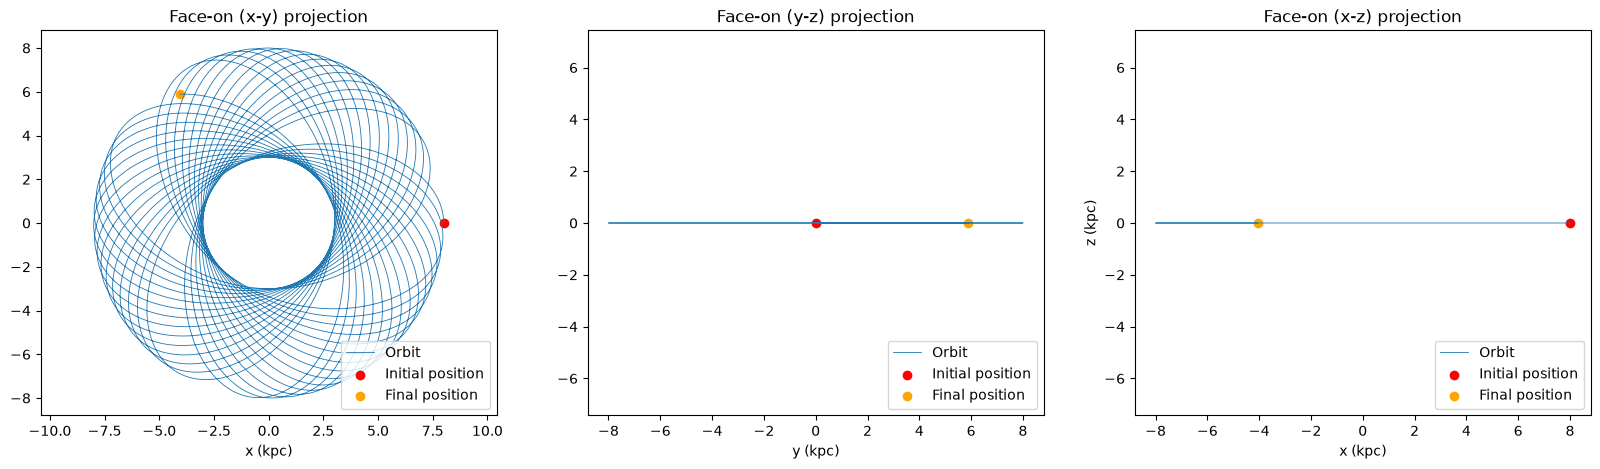

In [7]:
"""Gráficas de las órbitas en el marco inercial"""

fig, axes = plt.subplots(1, 3, figsize = (20,5))

axes[0].plot(soly[:,0], soly[:,1], lw=0.6, label = "Orbit")
axes[0].scatter(state0[0], state0[1], color = "r", label = "Initial position")
axes[0].scatter(soly[-1,0], soly[-1,1], color = "orange", label = "Final position")
axes[0].set_xlabel('x (kpc)'); plt.ylabel('y (kpc)')
axes[0].set_title('Face-on (x-y) projection')
axes[0].legend(loc = 4)
axes[0].axis("equal")

axes[1].plot(soly[:,1], soly[:,2], lw=0.6, label = "Orbit")
axes[1].scatter(state0[1], state0[2], color = "r", label = "Initial position")
axes[1].scatter(soly[-1,1], soly[-1,2], color = "orange", label = "Final position")
axes[1].set_xlabel('y (kpc)'); plt.ylabel('z (kpc)')
axes[1].set_title('Face-on (y-z) projection')
axes[1].legend(loc = 4)
axes[1].axis("equal")

axes[2].plot(soly[:,0], soly[:,2], lw=0.6, label = "Orbit")
axes[2].scatter(state0[0], state0[2], color = "r", label = "Initial position")
axes[2].scatter(soly[-1,0], soly[-1,2], color = "orange", label = "Final position")
axes[2].set_xlabel('x (kpc)'); plt.ylabel('z (kpc)')
axes[2].set_title('Face-on (x-z) projection')
axes[2].legend(loc = 4)
axes[2].axis("equal")

#plt.savefig("./images/orbits_each_planeRK45.png")
plt.show()

In [8]:
# Relative error in initial and final energy

e0 = T(state0) + pot(state0)
ef = T(soly[-1]) + pot(soly[-1])

error = err(e0, ef)
print(error)

l0 = l(state0); lz_0 = l0[2]
lf = l(soly[-1]); lz_f = lf[2]

error_lz = err(lz_0, lz_f)
print(error_lz)

4.082866949388219e-15
1.1102230246251442e-14


In [13]:
omega = np.array([0., 0., -2.3])
soly_rot = RV(soly, omega, ts)

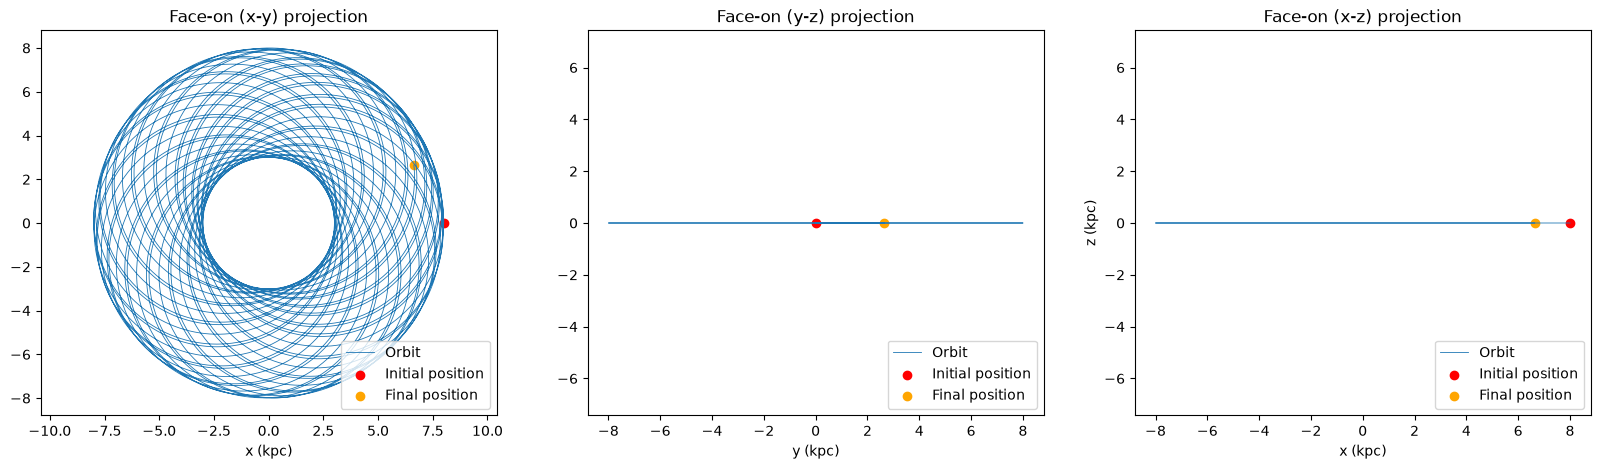

In [14]:
""" Órbitas en el marco no inercial """
fig, axes = plt.subplots(1, 3, figsize = (20,5))

axes[0].plot(soly_rot[:,0], soly_rot[:,1], lw=0.6, label = "Orbit")
axes[0].scatter(state0[0], state0[1], color = "r", label = "Initial position")
axes[0].scatter(soly_rot[-1,0], soly_rot[-1,1], color = "orange", label = "Final position")
axes[0].set_xlabel('x (kpc)'); plt.ylabel('y (kpc)')
axes[0].set_title('Face-on (x-y) projection')
axes[0].legend(loc = 4)
axes[0].axis("equal")

axes[1].plot(soly_rot[:,1], soly_rot[:,2], lw=0.6, label = "Orbit")
axes[1].scatter(state0[1], state0[2], color = "r", label = "Initial position")
axes[1].scatter(soly_rot[-1,1], soly_rot[-1,2], color = "orange", label = "Final position")
axes[1].set_xlabel('y (kpc)'); plt.ylabel('z (kpc)')
axes[1].set_title('Face-on (y-z) projection')
axes[1].legend(loc = 4)
axes[1].axis("equal")

axes[2].plot(soly_rot[:,0], soly_rot[:,2], lw=0.6, label = "Orbit")
axes[2].scatter(state0[0], state0[2], color = "r", label = "Initial position")
axes[2].scatter(soly_rot[-1,0], soly_rot[-1,2], color = "orange", label = "Final position")
axes[2].set_xlabel('x (kpc)'); plt.ylabel('z (kpc)')
axes[2].set_title('Face-on (x-z) projection')
axes[2].legend(loc = 4)
axes[2].axis("equal")

#plt.savefig("./images/orbits_each_planeRK45.png")
plt.show()

In [15]:
soly_rot = RinvV(soly_rot, omega, ts)

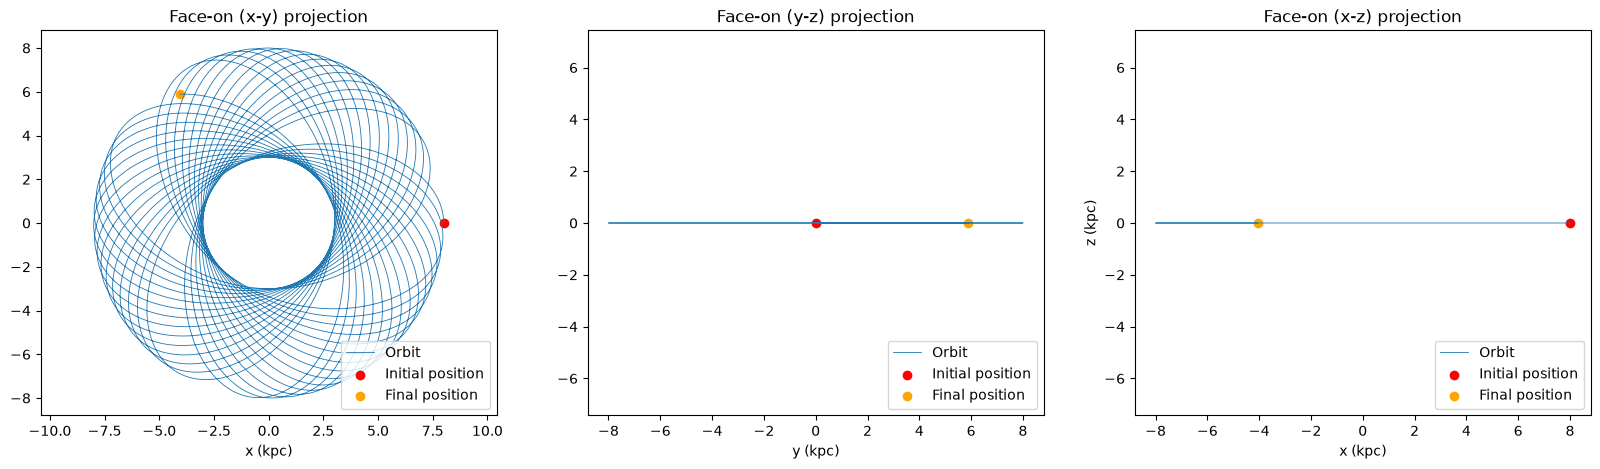

In [16]:
"""Gráficas de las órbitas en el marco inercial (De nuevo)"""

fig, axes = plt.subplots(1, 3, figsize = (20,5))

axes[0].plot(soly_rot[:,0], soly_rot[:,1], lw=0.6, label = "Orbit")
axes[0].scatter(state0[0], state0[1], color = "r", label = "Initial position")
axes[0].scatter(soly_rot[-1,0], soly_rot[-1,1], color = "orange", label = "Final position")
axes[0].set_xlabel('x (kpc)'); plt.ylabel('y (kpc)')
axes[0].set_title('Face-on (x-y) projection')
axes[0].legend(loc = 4)
axes[0].axis("equal")

axes[1].plot(soly_rot[:,1], soly_rot[:,2], lw=0.6, label = "Orbit")
axes[1].scatter(state0[1], state0[2], color = "r", label = "Initial position")
axes[1].scatter(soly_rot[-1,1], soly_rot[-1,2], color = "orange", label = "Final position")
axes[1].set_xlabel('y (kpc)'); plt.ylabel('z (kpc)')
axes[1].set_title('Face-on (y-z) projection')
axes[1].legend(loc = 4)
axes[1].axis("equal")

axes[2].plot(soly_rot[:,0], soly_rot[:,2], lw=0.6, label = "Orbit")
axes[2].scatter(state0[0], state0[2], color = "r", label = "Initial position")
axes[2].scatter(soly_rot[-1,0], soly_rot[-1,2], color = "orange", label = "Final position")
axes[2].set_xlabel('x (kpc)'); plt.ylabel('z (kpc)')
axes[2].set_title('Face-on (x-z) projection')
axes[2].legend(loc = 4)
axes[2].axis("equal")

#plt.savefig("./images/orbits_each_planeRK45.png")
plt.show()